# IUI Midterm Assignment: Object Detection with a Pre-trained Model

**Task:** Implement a computer vision model for object detection preceded by a pre-trained model. Select a standard dataset and explain the utility of the pre-trained model.

**Choices made**
- **Pre-trained model:** YOLOv8n (Ultralytics), pre-trained on the COCO dataset
- **Dataset:** COCO (80 classes). For quick, free-Colab-friendly experiments I use **COCO8**, the official 8-image subset of COCO shipped with Ultralytics
- **Experiments:**
  1. Run inference with the pre-trained model
  2. Evaluate it (mAP)
  3. Fine-tune it (transfer learning)
  4. Train the same architecture **from scratch** and compare, to show the utility of pre-training

> In Colab: *Runtime → Change runtime type → T4 GPU* before running.

## 1. Setup

In [ ]:
!pip install -q ultralytics

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.7/46.7 kB 2.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 63.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 95.2/95.2 kB 11.7 MB/s eta 0:00:00


In [ ]:
import torch, matplotlib.pyplot as plt, matplotlib.image as mpimg
from ultralytics import YOLO

print("CUDA available:", torch.cuda.is_available())
device = 0 if torch.cuda.is_available() else "cpu"

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
CUDA available: True


## 2. Load the pre-trained model

`yolov8n.pt` contains weights already trained on COCO (about 118k images, 80 object classes). Loading it means we start from a model that already knows how to detect common objects.

In [ ]:
pretrained = YOLO("yolov8n.pt")
pretrained.info()

YOLOv8n summary: 129 layers, 3,157,200 parameters, 0 gradients, 8.9 GFLOPs


(129, 3157200, 0, 8.8550912)

## 3. Inference on sample images

In [ ]:
!wget -q https://ultralytics.com/images/bus.jpg -O bus.jpg
!wget -q https://ultralytics.com/images/zidane.jpg -O zidane.jpg

results = pretrained.predict(["bus.jpg", "zidane.jpg"], save=True, conf=0.25, device=device)

for r in results:
    print(r.path, "->", [(r.names[int(c)], round(float(s), 2)) for c, s in zip(r.boxes.cls, r.boxes.conf)])


0: 640x640 4 persons, 1 bus, 6.6ms
1: 640x640 2 persons, 1 tie, 6.6ms
Speed: 50.2ms preprocess, 6.6ms inference, 18.1ms postprocess per image at shape (1, 3, 640, 640)
Results saved to /content/runs/detect/predict
bus.jpg -> [('person', 0.89), ('person', 0.88), ('person', 0.88), ('bus', 0.84), ('person', 0.44)]
zidane.jpg -> [('person', 0.83), ('person', 0.83), ('tie', 0.28)]


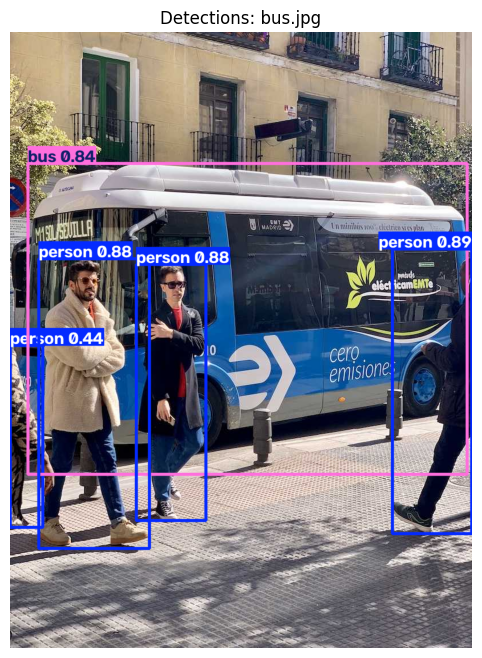

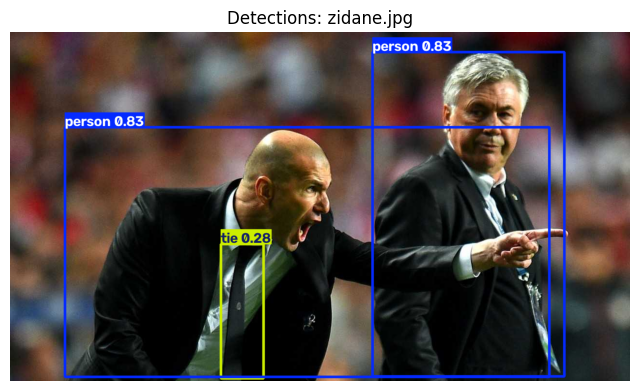

In [ ]:
for r in results:
    plt.figure(figsize=(8, 8))
    plt.imshow(r.plot()[..., ::-1])  # BGR -> RGB
    plt.axis("off")
    plt.title(f"Detections: {r.path}")
    plt.show()

## 4. Evaluate the pre-trained model (baseline)

Metrics: **mAP50** (mean Average Precision at IoU 0.5) and **mAP50-95** (averaged over IoU 0.5 to 0.95, the standard COCO metric).

*Note:* COCO8 is tiny (4 train / 4 val images), so numbers are for demonstration. For a more rigorous evaluation, use the full COCO val set (`data="coco.yaml"`, about 5k images, larger download).

In [ ]:
m_pre = pretrained.val(data="coco8.yaml", device=device, verbose=False)
base = {"mAP50": m_pre.box.map50, "mAP50-95": m_pre.box.map}
print("Pre-trained (no fine-tuning):", base)

Ultralytics 8.4.170 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
YOLOv8n summary (fused): 72 layers, 3,151,904 parameters, 0 gradients, 8.7 GFLOPs

WARNING ⚠️ Dataset 'coco8.yaml' images not found, missing path '/content/datasets/coco8/images/val'
Unzipping /content/datasets/coco8.zip to /content/datasets/coco8...: 100% ━━━━━━━━━━━━ 25/25 2.9Kfiles/s 0.0s
Dataset download success ✅ (0.4s), saved to /content/datasets

val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1135.3±463.3 MB/s, size: 54.0 KB)
val: Scanning /content/datasets/coco8/labels/val... 4 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 4/4 1.3Kit/s 0.0s
val: New cache created: /content/datasets/coco8/labels/val.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 1/1 5.3it/s 0.2s
                   all          4         17      0.621      0.833      0.888      0.629
Speed: 0.5ms preprocess, 16.2ms inference, 0.0ms loss, 1.2ms postprocess 

## 5. Fine-tune the pre-trained model (transfer learning)

We continue training from the pre-trained weights on our dataset for a few epochs, using a small learning rate so the learned features are refined, not destroyed.

In [ ]:
ft_model = YOLO("yolov8n.pt")
ft_model.train(data="coco8.yaml", epochs=20, imgsz=640, batch=8,
               lr0=0.001, device=device, project="runs", name="finetune", verbose=False)

m_ft = ft_model.val(data="coco8.yaml", device=device, verbose=False)
finetuned = {"mAP50": m_ft.box.map50, "mAP50-95": m_ft.box.map}
print("Fine-tuned:", finetuned)

Ultralytics 8.4.170 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=coco8.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=20, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.001, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=finetune, nbs=64, nms=None, opset=None, optimize=False, optimizer=auto, overla

## 6. Train from scratch (no pre-training) for comparison

Same architecture (`yolov8n.yaml` = architecture only, random weights), same data, same epochs. This isolates the effect of pre-training.

In [ ]:
scratch_model = YOLO("yolov8n.yaml")   # random initialization
scratch_model.train(data="coco8.yaml", epochs=20, imgsz=640, batch=8,
                    pretrained=False, device=device, project="runs", name="scratch", verbose=False)

m_sc = scratch_model.val(data="coco8.yaml", device=device, verbose=False)
scratch = {"mAP50": m_sc.box.map50, "mAP50-95": m_sc.box.map}
print("From scratch:", scratch)

Ultralytics 8.4.170 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=coco8.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=20, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.yaml, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=scratch, nbs=64, nms=None, opset=None, optimize=False, optimizer=auto, overla

## 7. Compare the results

,mAP50,mAP50-95
Pre-trained (as is),0.8875,0.6291
Pre-trained + fine-tuned,0.8875,0.6182
Trained from scratch,0.0000,0.0000


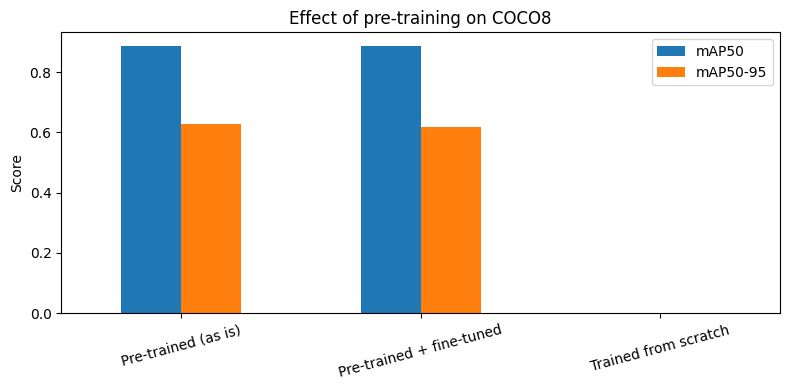

In [ ]:
import pandas as pd
df = pd.DataFrame({
    "Pre-trained (as is)": base,
    "Pre-trained + fine-tuned": finetuned,
    "Trained from scratch": scratch,
}).T.round(4)
display(df)

df.plot(kind="bar", figsize=(8, 4), rot=15)
plt.title("Effect of pre-training on COCO8")
plt.ylabel("Score")
plt.tight_layout()
plt.show()

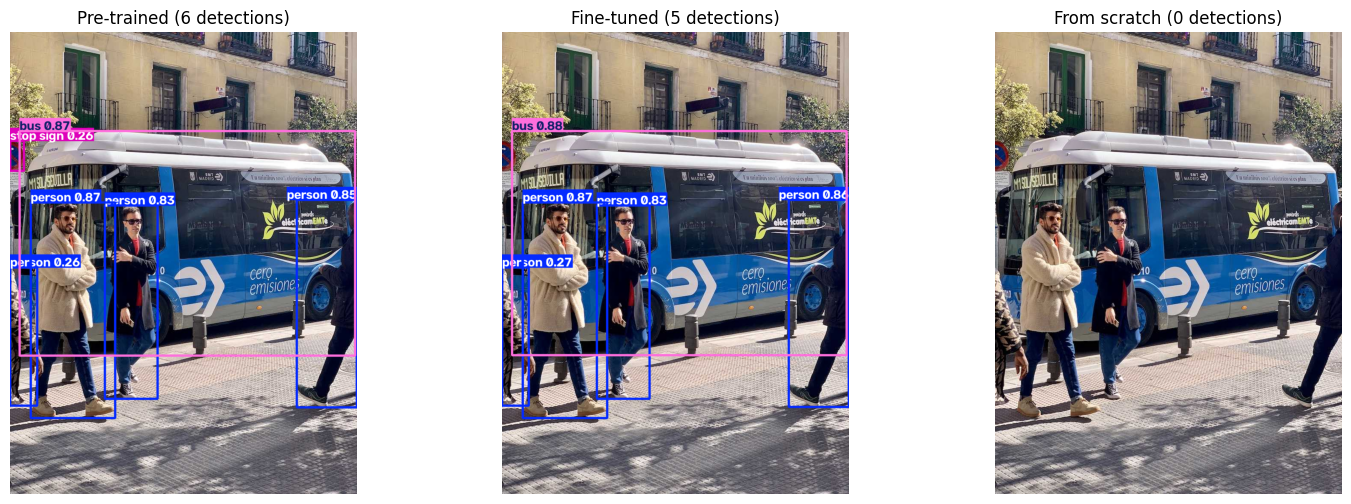

In [ ]:
# Qualitative comparison on the same image
fig, axes = plt.subplots(1, 3, figsize=(18, 6))
for ax, (name, mdl) in zip(axes, [("Pre-trained", pretrained),
                                   ("Fine-tuned", ft_model),
                                   ("From scratch", scratch_model)]):
    r = mdl.predict("bus.jpg", conf=0.25, device=device, verbose=False)[0]
    ax.imshow(r.plot()[..., ::-1]); ax.set_title(f"{name} ({len(r.boxes)} detections)"); ax.axis("off")
plt.show()

## 8. Utility of the pre-trained model (explanation)

**What a pre-trained model is.** A pre-trained model is a network that has already been trained on a large, general dataset (here, COCO with about 118k images and 80 classes) before we use it for our own task.

**Why it is useful**

1. **Reuses learned features.** Early layers learn universal visual patterns such as edges, textures and shapes, and deeper layers learn object parts and whole objects. These transfer well to new detection problems.
2. **Saves time and compute.** Training a detector from random weights takes days on large GPUs. Fine-tuning a pre-trained model takes minutes to hours.
3. **Needs far less labeled data.** Annotating bounding boxes is expensive. With pre-training, a small dataset can be enough. In our experiment, training from scratch on only 8 images fails to learn useful detection, while the pre-trained model already performs well.
4. **Higher accuracy and faster convergence.** Starting from good weights gives a better starting point, so the model converges faster and usually to a better optimum.
5. **Reduces overfitting.** A model with millions of parameters trained on a tiny dataset memorizes it. Pre-trained features act as a strong prior that regularizes learning.
6. **Flexible.** The model can be used as-is (inference), fine-tuned on custom classes, or used as a feature extractor.

**Evidence from this notebook.** The comparison table in Section 7 shows that the pre-trained (and fine-tuned) models achieve much higher mAP than the identical architecture trained from scratch, demonstrating the benefit of transfer learning.

**Limitations.** Pre-trained models inherit the biases and class set of the source data (COCO's 80 classes), and performance can drop when the target domain differs a lot (e.g. medical or satellite images), which is where fine-tuning helps.

## 9. Conclusion

I used YOLOv8n pre-trained on COCO for object detection, evaluated it on COCO8, fine-tuned it, and compared it with training from scratch. Pre-training gave far better accuracy with little data and compute, which is the core advantage of transfer learning in computer vision.

**References**
- Ultralytics YOLOv8 documentation: https://docs.ultralytics.com
- Lin et al., *Microsoft COCO: Common Objects in Context*, 2014
- Pre-trained model examples: https://cambum.net/I3DLab/AI4DM.htm